In [13]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Permite importar mibici al ejecutar desde notebooks/
ROOT = Path.cwd().resolve()
if not (ROOT / "mibici").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mibici import config
from mibici.features import features_p2

In [4]:
print("hola")

hola


In [ ]:
archivos = sorted(config.PROCESSED_DATA_DIR.glob("datos_abiertos_*.parquet"))
print("Meses disponibles:", len(archivos))
if not archivos:
    raise FileNotFoundError("No hay Parquet en data/raw/. Primero ejecuta la ingesta de dataset.py")
viajes = pd.read_parquet(archivos[0])
print("Archivo:", archivos[0].name, "| Viajes:", len(viajes))
display(viajes.head())

catalogos = sorted(config.PROCESSED_DATA_DIR.glob("*nomenclatura*.csv"))
if not catalogos:
    raise FileNotFoundError("No se encontró la nomenclatura en data/raw/")
try:
    estaciones = pd.read_csv(catalogos[-1], encoding="utf-8-sig")
except UnicodeDecodeError:
    estaciones = pd.read_csv(catalogos[-1], encoding="latin-1")
print("Catálogo:", catalogos[-1].name)
print("Columnas del catálogo:", estaciones.columns.tolist())
display(estaciones.head())

Meses disponibles: 40
Archivo: datos_abiertos_2023_06.parquet | Viajes: 339628


,viaje_id,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,28897410,2023-06-01 00:00:40,2023-06-01 00:09:26,20,255
1,28897411,2023-06-01 00:00:46,2023-06-01 00:13:33,20,12
2,28897412,2023-06-01 00:00:55,2023-06-01 00:01:10,273,273
3,28897413,2023-06-01 00:00:59,2023-06-01 00:12:41,273,246
4,28897414,2023-06-01 00:01:20,2023-06-01 00:12:33,273,246


Catálogo: nomenclatura_2026_09.csv
Columnas del catálogo: ['id', 'name', 'latitude', 'longitude', 'dpcapacity']


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


In [18]:
viajes["inicio_del_viaje"] = pd.to_datetime(viajes["inicio_del_viaje"])
viajes["fin_del_viaje"] = pd.to_datetime(viajes["fin_del_viaje"])
salidas = (viajes.assign(hora=viajes["inicio_del_viaje"].dt.floor("h"))
           .groupby(["origen_id", "hora"]).size().rename("salidas")
           .rename_axis(index={"origen_id": "estacion_id"}).reset_index())
llegadas = (viajes.assign(hora=viajes["fin_del_viaje"].dt.floor("h"))
            .groupby(["destino_id", "hora"]).size().rename("llegadas")
            .rename_axis(index={"destino_id": "estacion_id"}).reset_index())

est = estaciones.rename(columns={"id": "estacion_id", "dpcapacity": "capacidad"})
assert {"estacion_id", "capacidad"}.issubset(est.columns), "Revisar las columnas de nomenclatura"
est = est[["estacion_id", "capacidad"]].copy()
for df in (salidas, llegadas, est):
    df["estacion_id"] = pd.to_numeric(df["estacion_id"], errors="coerce")
est["capacidad"] = pd.to_numeric(est["capacidad"], errors="coerce")
est = est.dropna().drop_duplicates("estacion_id")

horas = pd.date_range(viajes["inicio_del_viaje"].min().floor("h"),
                      viajes["inicio_del_viaje"].max().ceil("h"), freq="h")
ids = pd.Index(pd.concat([salidas["estacion_id"], llegadas["estacion_id"]]).dropna().unique(), name="estacion_id")
malla = pd.MultiIndex.from_product([ids, horas], names=["estacion_id", "hora"]).to_frame(index=False)
malla = (malla.merge(salidas, on=["estacion_id", "hora"], how="left")
         .merge(llegadas, on=["estacion_id", "hora"], how="left")
         .merge(est, on="estacion_id", how="left"))
malla[["salidas", "llegadas"]] = malla[["salidas", "llegadas"]].fillna(0).astype(int)
malla = malla.dropna(subset=["capacidad"]).query("capacidad > 0").sort_values(["estacion_id", "hora"]).reset_index(drop=True)
malla["saldo"] = malla["llegadas"] - malla["salidas"]
print("Estaciones:", malla["estacion_id"].nunique(), "| Filas estación-hora:", len(malla))
display(malla.head())

Estaciones: 300 | Filas estación-hora: 216300


,estacion_id,hora,salidas,llegadas,capacidad,saldo
0,2,2023-06-01 00:00:00,0,0,15,0
1,2,2023-06-01 01:00:00,0,0,15,0
2,2,2023-06-01 02:00:00,0,0,15,0
3,2,2023-06-01 03:00:00,0,0,15,0
4,2,2023-06-01 04:00:00,0,0,15,0


,salidas,llegadas,saldo,capacidad
count,216300.000000,216300.000000,216300.000000,216300.000000
mean,1.570171,1.570166,-0.000005,16.690000
std,2.659731,2.760589,2.088244,4.378811
min,0.000000,0.000000,-71.000000,11.000000
25%,0.000000,0.000000,-1.000000,15.000000
50%,1.000000,1.000000,0.000000,15.000000
75%,2.000000,2.000000,0.000000,19.000000
max,80.000000,97.000000,71.000000,39.000000


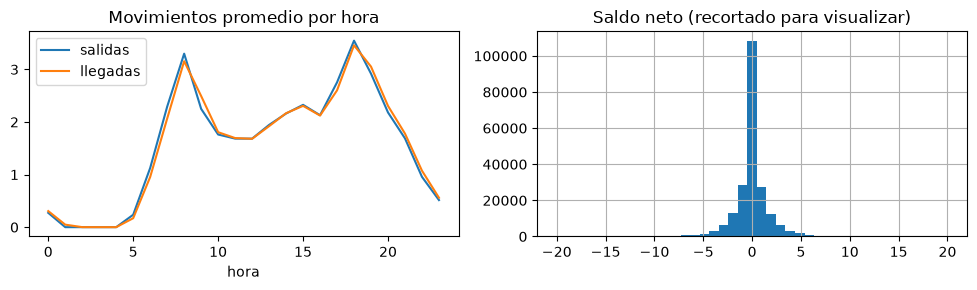

In [19]:
display(malla[["salidas", "llegadas", "saldo", "capacidad"]].describe())
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
malla.groupby(malla["hora"].dt.hour)[["salidas", "llegadas"]].mean().plot(ax=axes[0], title="Movimientos promedio por hora")
malla["saldo"].clip(-20, 20).hist(bins=41, ax=axes[1]); axes[1].set_title("Saldo neto (recortado para visualizar)")
plt.tight_layout(); plt.show()

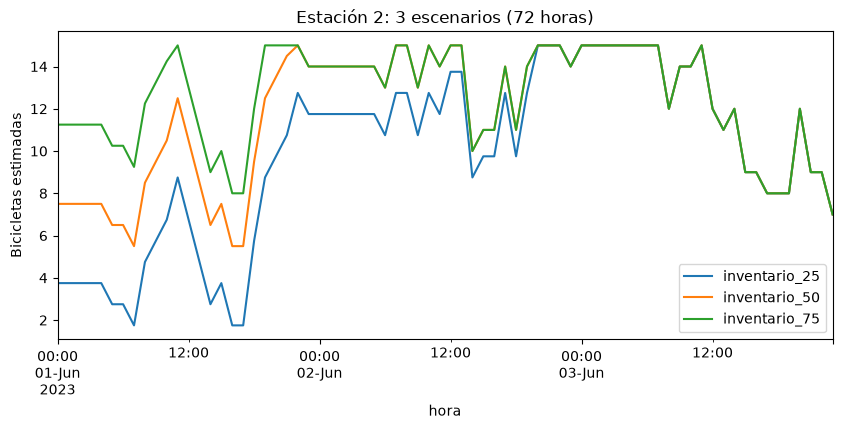

In [20]:
def inventario_por_hora(malla, porcentaje_inicial):
    resultado = malla.sort_values(["estacion_id", "hora"]).copy()
    inventarios = pd.Series(index=resultado.index, dtype=float)
    for _, grupo in resultado.groupby("estacion_id", sort=False):
        capacidad = float(grupo["capacidad"].iloc[0])
        inventario = capacidad * porcentaje_inicial
        for idx, fila in grupo.iterrows():
            inventario = np.clip(inventario + fila["llegadas"] - fila["salidas"], 0, capacidad)
            inventarios.loc[idx] = inventario
    return inventarios

for porcentaje in (0.25, 0.50, 0.75):
    malla[f"inventario_{int(porcentaje * 100)}"] = inventario_por_hora(malla, porcentaje)

estacion_ejemplo = malla["estacion_id"].value_counts().index[0]
ejemplo = malla[malla["estacion_id"] == estacion_ejemplo].head(72)
ejemplo.plot(x="hora", y=["inventario_25", "inventario_50", "inventario_75"], figsize=(10, 4), title=f"Estación {estacion_ejemplo}: 3 escenarios (72 horas)")
plt.ylabel("Bicicletas estimadas"); plt.show()

In [22]:
for porcentaje in (25, 50, 75):
    inv = malla[f"inventario_{porcentaje}"]
    siguiente = inv.groupby(malla["estacion_id"]).shift(-1)
    validos = siguiente.notna()
    riesgo = (siguiente <= 0.10 * malla["capacidad"]) | (siguiente >= 0.90 * malla["capacidad"])
    print(f"Inicio {porcentaje}%: riesgo t+1 = {riesgo[validos].mean():.1%} de las filas con futuro disponible")

Inicio 25%: riesgo t+1 = 50.6% de las filas con futuro disponible
Inicio 50%: riesgo t+1 = 49.7% de las filas con futuro disponible
Inicio 75%: riesgo t+1 = 48.6% de las filas con futuro disponible
